# GEFS v12 → dHBV → CRPS/CRPSS (continuous simulation only)

- `gefs_crpss.py`: NPZ forecast and simulation storage, temporal alignment, CRPS equations, CRPSS, deterministic scores, figures/CSV.
- `tempfunctions.py`: underlying HBV simulation, GEFS forcing, restart, and corrections (unchanged).

**Array dimensions:** saved GEFS forecast `(M,L)`; loaded forecasts `(I,L,M)`; simulation dates/flow `(T,)`; aligned simulated targets `(I,L)`; prior-day simulated flow `(I,)`; CRPS cases `(I,L)`; mean score by lead `(L,)`.

With `LEAD1_OFFSET=0`, GEFS Day 1 verifies on initialization date and the persistence reference comes from the previous day's continuous simulated streamflow. If GEFS `.npz` files already exist, leave `RUN_FORECASTS=False`; continuous simulations are generated or loaded in their own cell.


## 1. Load configuration and dataset

The data loader supplies the HBV model inputs, total number of daily timesteps, and basin-column ordering. 

In [2]:
import sys
sys.path.append('../../') 
from src.dmg import ModelHandler 
from src.dmg.core.utils import import_data_loader, print_config, print_dataset_info, set_randomseed
from tempfunctions import *
from example import load_config 
#------------------------------------------#
# Define model settings here.
from tempfunctions import get_config_path

MODEL_TYPE = "d3"   # change only this: "d3", "d2", or "static"
CONFIG_PATH = get_config_path(MODEL_TYPE)
#------------------------------------------#

# 1. Load configuration dictionary of model parameters and options.
config = load_config(CONFIG_PATH)
config['mode'] = 'sim'

print_config(config)
# print("Config Keys:", config.keys())
# print("config['multimodel_type']", config['multimodel_type'])
# Set random seed for reproducibility.
set_randomseed(config['seed'])

# 2. Initialize the differentiable HBV 1.1p model (LSTM + HBV 1.1p).
model = ModelHandler(config, verbose=True) # model key is ['Hbv_1_1p'] 
nn_model = model.model_dict["Hbv_1_1p"].nn_model

# 3. Load and initialize a dataset dictionary of NN and HBV model inputs.
data_loader_cls = import_data_loader(config['data_loader'])
data_loader = data_loader_cls(config, test_split=False, overwrite=False)
print_dataset_info(data_loader.dataset)    


Current Configuration
  Experiment Mode:    sim                 
  Model 1:            Hbv_1_1p            
  Dynamic Params:     ['parBETA', 'parK0', 'parBETAET']

Data Loader
  Data Source:        camels_531          
  Simulation Range :  2009/10/01          2013/09/30          

Experiment Parameters
  Train Epochs:       100                 Batch Size:         100                 
  Start Epoch:        0                   Save Epoch:         5                   
  Loss Fn:            NseBatchLoss        
  Optimizer:          Adadelta            LR Scheduler:       None                

Machine
  Device:             cuda:0              
  Dtype:              torch.float32       


Dataset Inputs
Dataset key    Shape               Description
------------------------------------------------------------
x_phy          (1461, 531, 3)       # [time, basin, forcing_features]
c_phy          (531, 0)             # [basin, attr_features] (no physical attributes here)
x_nn           (1461

## 2. Experiment settings and basin selection

`MODE` selects one or many basins for both forecast generation and simulated-reference evaluation. `CLIMATOLOGY_YEARS=None` uses the full continuous simulation, including dates in the test period. Set it to historical years for out-of-sample climatology.

In [3]:
# Forecast experiment and dataset conventions
START_DATE, END_DATE = "2012-01-01", "2012-12-31"
YEAR = 2012
PRE, WINDOW, POST = "scalar", 30, True
N_LEADS, N_ENSEMBLES, WARMUP = 10, 5, 365
LEAD1_OFFSET = 0       # GEFS Day 1 is the initialization date
MIN_VALID_CASES = 30 
CLIMATOLOGY_YEARS = None  # Original scores; or [2010, 2011] for pre-2012 climatology

MODE = "single"         # "single" or "multiple"
BASIN_SET = "best_36" # "best_36", "camels_531", "all_loaded"

SINGLE_BASIN_ID = "01031500" # "14306500" #"01139000" # "01137500"
SKIP_EXISTING = True # false if you want to overwrite the short-time forecast testings of certain basins, true if you want to skip

gage_ids = np.load(config["observations"]["gage_info"], allow_pickle=True)
subset_file = config["observations"]["subset_path"]
with open(subset_file, "r") as f:
    raw_subset = f.read().strip()
gage_ids_subset = (
    json.loads(raw_subset) if raw_subset.startswith("[")
    else np.loadtxt(subset_file, dtype=int).reshape(-1).tolist()
)

obs_name = config["observations"]["name"]
if obs_name == "camels_671":
    loader_basin_pool = [int(b) for b in gage_ids]
elif obs_name == "camels_531":
    loader_basin_pool = [int(b) for b in gage_ids_subset]
else:
    raise ValueError(f"Unexpected CAMELS observations name: {obs_name}")

if MODE == "single":
    eval_basins = [int(SINGLE_BASIN_ID)]
elif MODE == "multiple":
    if BASIN_SET == "best_36":
        eval_basins = [
            int(b) for b in tempfunctions.selectbasins()
        ]
    elif BASIN_SET == "camels_531":
        eval_basins = [
            int(b) for b in gage_ids_subset
        ]
    elif BASIN_SET == "all_loaded":
        eval_basins = list(loader_basin_pool)
    else:
        raise ValueError(f"Unknown BASIN_SET: {BASIN_SET}")
else:
    raise ValueError(f"Unknown MODE: {MODE}")

missing = sorted(set(eval_basins).difference(loader_basin_pool))
if missing:
    raise ValueError(f"Basins not in data-loader ordering: {missing}")

save_root = gefs.forecast_root(config, START_DATE, END_DATE, PRE, WINDOW, POST)
print("# of selected basins for evaluation:", len(eval_basins))
print("Saved to forecast folder:", save_root) 

# of selected basins for evaluation: 1
Saved to forecast folder: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True


## 3. Generate year-long short-time forecasts and save daily NPZ forecasts

Set `RUN_FORECASTS=True` and rerun this cell **only** to generate missing short-time forecasts. Generation calls `tempfunctions.run_segment()` and `tempfunctions.run_warm_forecasts_restart()` for each date; `.npz` saving is performed by `gefs.save_forecast_npz()`. Existing `.npz` forecasts remain unchanged when `SKIP_EXISTING=True`.

**IMPORTANT:** The original `tempfunctions` GEFS restart callback assumes a bias correction (`PRE="scalar"` or `"cdf"`). This notebook uses `"scalar"`.  

In [6]:
RUN_FORECASTS = False    # False if reuse .npz short-time forecasts 

if RUN_FORECASTS:
    model = ModelHandler(config, verbose=True)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    gefs_results, failed_basins = {}, {}

    for position, gage_id in enumerate(eval_basins, start=1):
        print(f"Basin {position}/{len(eval_basins)}: {gage_id:08d}")
        try:
            result = gefs.run_gefs_one_year(
                GAGE_ID=gage_id,
                model=model,
                data_loader=data_loader,
                config=config,
                basin_pool=loader_basin_pool,  # ORDER MUST MATCH data_loader
                startid_endid=tempfunctions.startid_endid,
                run_segment=tempfunctions.run_segment,
                run_warm_forecasts_restart=tempfunctions.run_warm_forecasts_restart,
                post_processing=tempfunctions.post_processing,
                START_DATE=START_DATE, END_DATE=END_DATE,
                FORECAST=N_LEADS, N_ENSEMBLES=N_ENSEMBLES, WARMUP=WARMUP,
                WINDOW=WINDOW, PRE=PRE, POST=POST,
                device=device, skip_existing=SKIP_EXISTING,
            )
            gefs_results[gage_id] = result
            if result["n_failed"]:
                failed_basins[gage_id] = result["failed_dates"]
        except Exception as exc:
            failed_basins[gage_id] = str(exc)
            print(f"FAILED {gage_id:08d}: {exc}")

    gefs.print_gefs_summary(eval_basins, gefs_results, failed_basins)
else:
    print("Skipped HBV short-time forecast generation; existing NPZ files will be used.")

Skipped HBV short-time forecast generation; existing NPZ files will be used.


## 4. Create cache continuous Daymet–HBV simulations

`build_basin_results()` creates the dated basin records without extracting observed discharge. The next cell attaches `sim` for **every selected basin**, generating or loading a trusted cached continuous Daymet–HBV simulation. This is to generate the simulaton forecast data for computing CRPSS_ref,ad.

In [9]:
basin_results = gefs.build_basin_results(
    data_loader=data_loader,
    config=config,
    loader_basin_pool=loader_basin_pool,
    selected_basins=eval_basins,
    WARMUP=WARMUP,
)
print("Observation data prepared for", len(basin_results), "basin")

Observation data prepared for 1 basin


In [14]:
import numpy as np
import pandas as pd
import torch
from pathlib import Path 

RUN_CONTINUOUS_SIM = False  # True if you want to generate continuous HBV simulations if not cached before 

SIM_DIR = Path(config["sim_dir"]) / "continuous_daymet_reference"
SIM_DIR.mkdir(parents=True, exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
reference_model = None
 
for gage_id in eval_basins:
    gage_id = int(gage_id)
    basin_key = f"{gage_id:08d}"
    basin_idx = loader_basin_pool.index(gage_id)
    save_path = SIM_DIR / f"reference_{basin_key}.npz"
    expected_dates = pd.DatetimeIndex(basin_results[basin_key]["dates"]).normalize()

    if save_path.exists():
        # Older user-generated cache files stored object-typed dates.
        # Only enable legacy pickle loading for files you created and trust.
        qsim, saved_dates, saved_basin = gefs.load_simulation_npz(
            save_path, allow_legacy_pickle=True
        )
        if saved_basin != basin_key or not saved_dates.equals(expected_dates):
            raise ValueError(f"{basin_key}: cached simulation basin/date mismatch")
        print(f"Loaded previously-cached continuous HBV simulation: {basin_key}")

        # Convert trusted older cache to native datetime64[D]; subsequent reads
        # can use allow_legacy_pickle=False. No HBV computation required.
        with np.load(save_path, allow_pickle=True) as cache:
            old_dates = (cache["dates"].dtype == object)
        if old_dates:
            gefs.save_simulation_npz(save_path, basin_key, saved_dates, qsim)
            print(f"Converted legacy dates to safe dtype: {basin_key}")

    elif RUN_CONTINUOUS_SIM:
        if reference_model is None:
            reference_model = ModelHandler(config, verbose=True)
            reference_model.eval()
            # Verify that this handler uses your intended calibrated checkpoint.

        qsim = tempfunctions.run_segment(
            model=reference_model,
            dataset=data_loader.dataset,
            basin_idx=basin_idx,
            device=device,
            start_idx=None,
            end_idx=None,
            warm_up=WARMUP,
            cache_states=False,
            warm_up_states=True,
        )
        qsim = np.asarray(qsim, dtype=float).reshape(-1)
        n_total = data_loader.dataset["target"].shape[0]
        if len(qsim) == n_total:
            # Only trim when run_segment returned the entire input length.
            qsim = qsim[WARMUP:]
        if len(qsim) != len(expected_dates):
            raise ValueError(
                f"{basin_key}: qsim length {len(qsim)} != "
                f"expected {len(expected_dates)}"
            )
        gefs.save_simulation_npz(save_path, basin_key, expected_dates, qsim)
        print(f"Saved continuous simulation: {basin_key}")
    else:
        raise FileNotFoundError(f"Missing continuous simulation: {save_path}")

    if qsim.shape != (len(expected_dates),):
        raise ValueError(f"{basin_key}: invalid qsim shape {qsim.shape}")
    basin_results[basin_key]["sim"] = qsim
    print(f"{basin_key}: sim={qsim.shape}, dates={expected_dates[0].date()} to {expected_dates[-1].date()}")

print("All selected basins for evaluation have done continuous simulated reference flow.")

Loaded previously-cached continuous HBV simulation: 01031500
01031500: sim=(1096,), dates=2010-10-01 to 2013-09-30
All selected basins for evaluation have done continuous simulated reference flow.


## 5. Generate CRPSS figures from cached NPZ files of year-long daily-initialized short-term forecasts
Note that run_gefs_crpss() reads previously generated GEFS forecast .npz files rather than rerunning the forecasting model.
## 5.1 Generate CRPSS figures for single- or multiple- selected basins

[1/1] 01031500: 362 forecasts


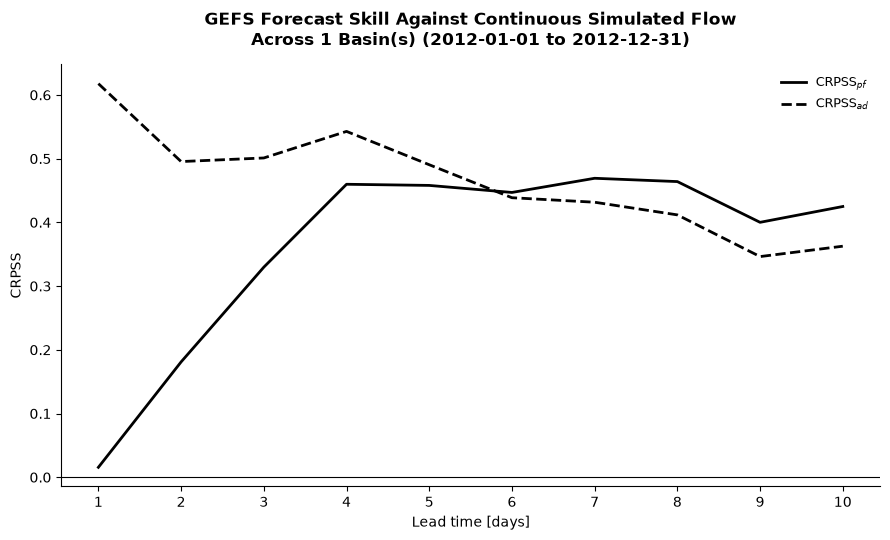

Evaluated: 1; failed: 0
Figure: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/CRPSS_simulated_single/CRPSS_01031500_simulated_2012.png
CSV: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/CRPSS_simulated_single/CRPSS_single_simulated_2012.csv


In [20]:
# Check if there is any missing continuous HVBV results saved
missing_sim = [f"{int(b):08d}" for b in eval_basins
               if "sim" not in basin_results[f"{int(b):08d}"]]
if missing_sim:
    raise ValueError(f"Missing continuous simulations for {missing_sim[:10]}")

# Run the year-long initialization dates to compute crpss
crpss_results = gefs.run_gefs_crpss(
    mode=MODE,
    config=config,
    basin_results=basin_results,
    basin_pool=eval_basins,
    GAGE_ID=eval_basins[0] if MODE == "single" else None,
    START_DATE=START_DATE, END_DATE=END_DATE,
    PRE=PRE, WINDOW=WINDOW, POST=POST,
    YEAR=YEAR, N_LEADS=N_LEADS, N_ENSEMBLES=N_ENSEMBLES,
    LEAD1_OFFSET=LEAD1_OFFSET,
    MIN_VALID_CASES=MIN_VALID_CASES,
    CLIMATOLOGY_YEARS=CLIMATOLOGY_YEARS,
    show_plot=True,
)
# display(crpss_results["results_df"])

## 5.2 Generate CRPSS figures for all available basins 
All available basins data should be the pre-generated basin folders under the path, eg. for HBV3 dynamics: znprojects/generic_deltamodel/example/hydrology/output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/..

Original basins: 113

Excluded basins: 32

Remaining basins: 81


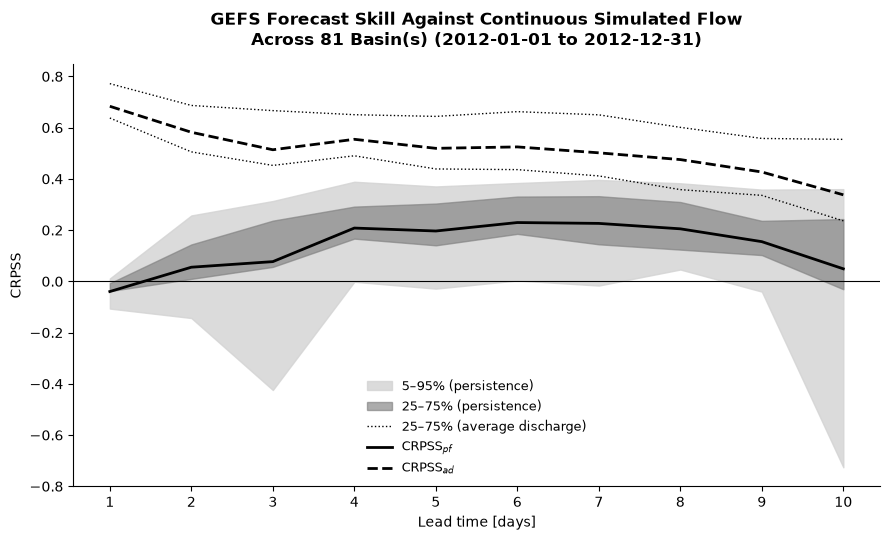


Figure saved to: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/CRPSS_simulated_multiple/filtered_below_(-1.5)/CRPSS_filtered.png


In [23]:
from pathlib import Path
import gefs_crpss as gefs

# 0. Set the threshold to filter out outliers with extreme negative crpss value
CRPSS_THRESHOLD = -1.5
CHECK_METRICS = ["CRPSS_pf", "CRPSS_ad"] # Choose which metrics determine exclusion
 
# 1. Read existing multi-basin CRPSS results 
csv_path = Path(save_root) / "CRPSS_simulated_multiple" / f"CRPSS_multiple_simulated_{YEAR}.csv"
df = pd.read_csv(csv_path, dtype={"basin_id": str})
df["basin_id"] = df["basin_id"].str.zfill(8)
print("Original basins:", df["basin_id"].nunique())

# 2. Identify extreme basins
extreme_rows = df[df[CHECK_METRICS].lt(CRPSS_THRESHOLD).any(axis=1)]
excluded_basins = set(extreme_rows["basin_id"])
print("\nExcluded basins:", len(excluded_basins))
# print(extreme_rows[["basin_id", "lead_time"] + CHECK_METRICS].sort_values("basin_id").to_string(index=False))
 
# 3. Remove entire basins 
filtered_df = df[~df["basin_id"].isin(excluded_basins)].copy()
n_basins = filtered_df["basin_id"].nunique()
print("\nRemaining basins:", n_basins)
if n_basins == 0: raise ValueError("No basins remain. Lower the exclusion threshold.")
 
# 4. Recalculate spatial summary (NO CRPS recomputation) 
g = filtered_df.groupby("lead_time")
summary = pd.DataFrame({"lead_time": sorted(filtered_df["lead_time"].unique())})

for metric, prefix in [
    ("CRPSS_pf", "CRPSS_pf"),
    ("CRPSS_ad", "CRPSS_ad"),
]:
    grouped = g[metric]

    summary[f"{prefix}_mean"] = summary["lead_time"].map(grouped.mean())

    for percentile in [5, 25, 75, 95]:
        summary[f"{prefix}_p{percentile:02d}"] = (
            summary["lead_time"].map(
                grouped.quantile(percentile / 100)
            )
        )
        
# 5. Save filtered CSV and figure 
output_dir = csv_path.parent / f"filtered_below_({CRPSS_THRESHOLD})"
output_dir.mkdir(parents=True, exist_ok=True)
filtered_df.to_csv(output_dir / "CRPSS_filtered.csv", index=False)
summary.to_csv(output_dir / "CRPSS_summary_filtered.csv", index=False)

gefs.plot_crpss(
    summary,
    mode="multiple",
    n_basins=n_basins, 
    start_date=START_DATE,
    end_date=END_DATE,
    save_path=output_dir / "CRPSS_filtered.png",
    show_plot=True,
)
print("\nFigure saved to:", output_dir / "CRPSS_filtered.png")

## 5.3. Doublecheck the dimensions

In [9]:
DIAG_BASIN_ID = int(eval_basins[0])  # Select basin for detailed diagnostics

forecasts, init_dates = gefs.load_basin_forecasts(
    save_root, DIAG_BASIN_ID,
    year=YEAR, start_date=START_DATE, end_date=END_DATE,
    n_members=N_ENSEMBLES, n_leads=N_LEADS,
)
qsim_series = gefs.simulated_series(basin_results, DIAG_BASIN_ID)
target_flow, initial_flow = gefs.align_reference(
    qsim_series, init_dates, N_LEADS, LEAD1_OFFSET
)
valid = gefs.valid_forecast_cases(forecasts, target_flow, initial_flow)
crps_cases = gefs.ensemble_crps_cases(forecasts, target_flow)
ensemble_mean = np.mean(forecasts, axis=2)

print("forecasts:", forecasts.shape, "(I,L,M)")
print("init_dates:", init_dates.shape, "(I,)")
print("target_flow:", target_flow.shape, "(I,L)")
print("initial_flow:", initial_flow.shape, "(I,)")
print("crps_cases:", crps_cases.shape, "(I,L)")
print("valid by lead:", valid.sum(axis=0))
print("Direct single-case CRPS check:", gefs.crps_single(forecasts[0, 0, :], target_flow[0, 0]))
print("Array CRPS at same position:", crps_cases[0, 0])

forecasts: (362, 10, 5) (I,L,M)
init_dates: (362,) (I,)
target_flow: (362, 10) (I,L)
initial_flow: (362,) (I,)
crps_cases: (362, 10) (I,L)
valid by lead: [362 362 362 362 362 362 362 362 362 362]
Direct single-case CRPS check: 0.29468637704849243
Array CRPS at same position: 0.29468637704849243


## 6. Additional deterministic scores against continuous simulated discharge

NS, Pbias and CV use the ensemble-mean forecast `(I,L)` compared with the **same aligned simulated streamflow** `target_flow (I,L)` (not observed discharge). These reuse the forecasts already loaded in Section 5.


,lead_time,NS,Pbias_pct,CV
0,1,0.580389,0.256809,0.909101
1,2,0.070887,-4.446048,1.356393
2,3,0.205033,-8.815847,1.256493
3,4,0.332475,-11.676274,1.153981
4,5,0.314737,-8.134277,1.168551
5,6,-0.089529,-15.974797,1.475297
6,7,-0.460311,-15.417048,1.708576
7,8,-0.966887,-23.949360,1.990805
8,9,-1.267488,-37.172909,2.068952
9,10,-0.080207,-27.322852,1.468532


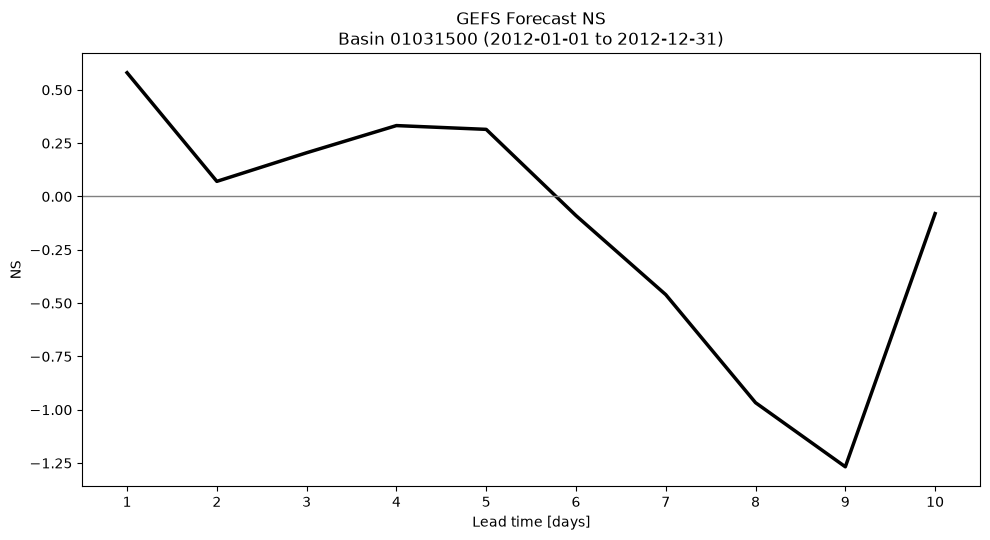

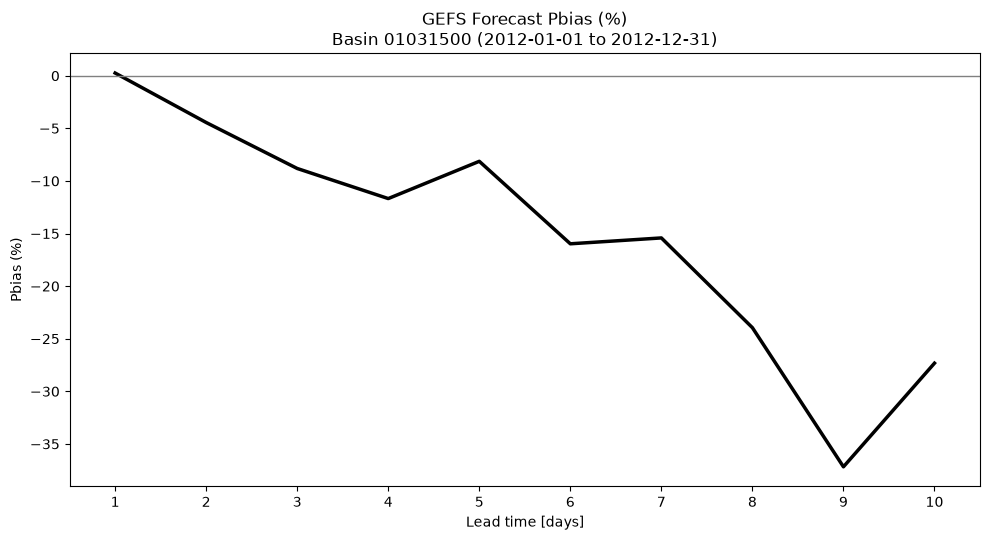

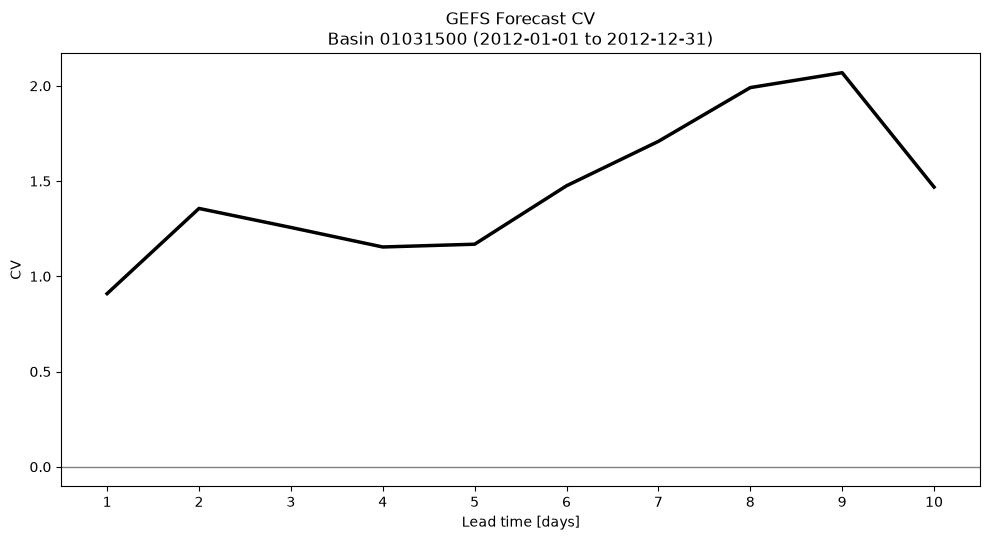

Metrics saved under: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/Evaluation_plots/01031500


In [10]:
ns = gefs.calculate_gefs_ns(ensemble_mean, target_flow, MIN_VALID_CASES)
pbias = gefs.calculate_gefs_pbias(ensemble_mean, target_flow, MIN_VALID_CASES)
cv = gefs.calculate_gefs_cv(ensemble_mean, target_flow, MIN_VALID_CASES)

metric_df = pd.DataFrame({
    "lead_time": np.arange(1, N_LEADS + 1),
    "NS": ns,
    "Pbias_pct": pbias,
    "CV": cv,
})
display(metric_df)

plot_dir = save_root / "Evaluation_plots" / f"{DIAG_BASIN_ID:08d}"
for values, metric_name in [(ns, "NS"), (pbias, "Pbias (%)"), (cv, "CV")]:
    gefs.plot_gefs_metric(
        values, metric_name, save_dir=plot_dir,
        START_DATE=START_DATE, END_DATE=END_DATE, basin_id=DIAG_BASIN_ID,
    )
print("Metrics saved under:", plot_dir)

## 7. Plot using available multiple basins
 
keep your basin selection and CRPSS computation unchanged, but when generating the multi-basin plot, only include basins that have available forecast folders and calculated CRPSS results

========== BASIN AVAILABILITY ==========
Available GEFS basins: 113
Basins already in CSV: 113
Available basins missing CRPSS: 0

========== CRPSS COVERAGE ==========
Available forecast basins: 113
Basins with CRPSS: 113
Missing CRPSS basins: []

========== OUTLIER FILTER ==========
CRPSS threshold: -1
Metrics: ['CRPSS_pf', 'CRPSS_ad']
Excluded basins: 34

Extreme CRPSS cases:
basin_id  lead_time       CRPSS_pf      CRPSS_ad
01451800          1      -3.382379      0.026030
01451800          2      -1.966779      0.009255
01451800          3      -1.401603     -0.003762
01451800          4      -1.119911     -0.014803
01451800         10      -1.073018     -0.240565
01491000          3      -1.218015      0.097342
02177000          1      -2.831326     -0.349168
02177000          2      -1.818192     -0.327777
02177000          3      -1.628768     -0.338509
02177000          4      -1.598171     -0.429305
02177000          5      -1.360048     -0.344798
02177000          6      -1.6915

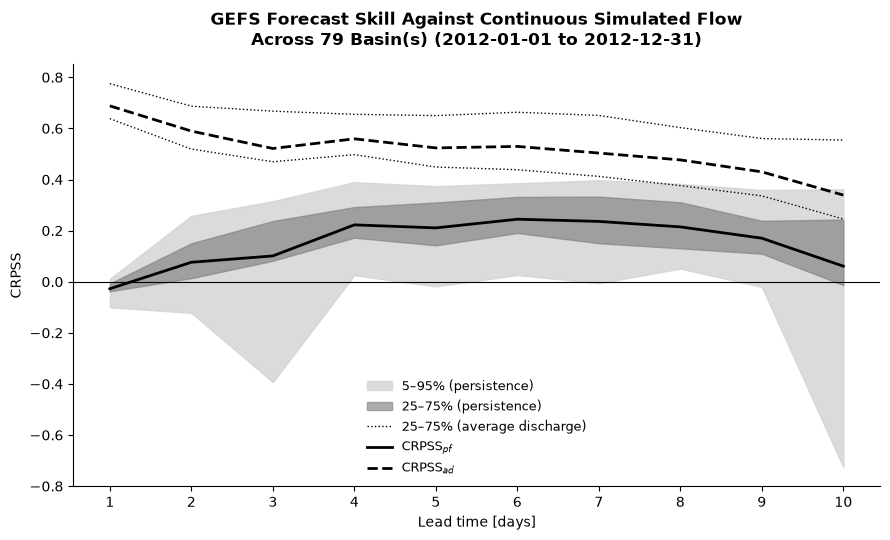


========== COMPLETE ==========
Original available basins: 113
Successfully evaluated: 113
Excluded: 34
Plotted basins: 79
Figure: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/CRPSS_simulated_multiple/available_filtered_-1/CRPSS_filtered.png
Filtered CSV: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/CRPSS_simulated_multiple/available_filtered_-1/CRPSS_filtered.csv


In [11]:
from pathlib import Path
import shutil
import gefs_crpss as gefs

# ==========================================
# Settings
# ==========================================
CRPSS_THRESHOLD = -1
CHECK_METRICS = ["CRPSS_pf", "CRPSS_ad"]

# True: calculate CRPSS for all available basins if CSV is incomplete
# False: only use existing CSV; raise error if basins are missing
EVALUATE_IF_MISSING = True

# ==========================================
# 1. Find ALL available GEFS basins
# ==========================================
save_root = Path(save_root)

available_basins = sorted([
    p.name.zfill(8)
    for p in save_root.iterdir()
    if p.is_dir()
    and p.name.isdigit()
    and any(p.glob("forecast_*.npz"))
])

available_ids = set(available_basins)

print("========== BASIN AVAILABILITY ==========")
print("Available GEFS basins:", len(available_basins))

if not available_basins:
    raise ValueError("No forecast NPZ files found.")

# ==========================================
# 2. Load existing CRPSS CSV
# ==========================================
csv_path = (
    save_root
    / "CRPSS_simulated_multiple"
    / f"CRPSS_multiple_simulated_{YEAR}.csv"
)

if csv_path.exists():
    df = pd.read_csv(csv_path, dtype={"basin_id": str})
    df["basin_id"] = df["basin_id"].str.zfill(8)
    csv_ids = set(df["basin_id"])
else:
    df = pd.DataFrame()
    csv_ids = set()

missing_crpss = available_ids - csv_ids

print("Basins already in CSV:", len(available_ids & csv_ids))
print("Available basins missing CRPSS:", len(missing_crpss))

# ==========================================
# 3. Evaluate available basins if needed
# ==========================================
if missing_crpss:

    if not EVALUATE_IF_MISSING:
        raise ValueError(
            f"{len(missing_crpss)} available basins have no CRPSS. "
            "Set EVALUATE_IF_MISSING=True to evaluate them."
        )

    # All basins need continuous Daymet-HBV simulations
    missing_sim = [
        b for b in available_basins
        if b not in basin_results
        or "sim" not in basin_results[b]
    ]

    if missing_sim:
        raise ValueError(
            f"Missing continuous simulations for "
            f"{len(missing_sim)} basins: {missing_sim[:15]}. "
            "Generate/load their sim references before CRPSS evaluation."
        )

    # Backup existing multiple-basin outputs before overwriting
    if csv_path.parent.exists():
        backup_dir = csv_path.parent / "backup_before_available_run"
        backup_dir.mkdir(parents=True, exist_ok=True)

        for file in csv_path.parent.iterdir():
            if file.is_file() and file.suffix in (".csv", ".png"):
                destination = backup_dir / file.name
                if not destination.exists():
                    shutil.copy2(file, destination)

    print("\nEvaluating all available GEFS basins...")

    all_crpss_results = gefs.run_gefs_crpss(
        mode="multiple",
        config=config,
        basin_results=basin_results,
        basin_pool=[int(b) for b in available_basins],
        GAGE_ID=None,
        START_DATE=START_DATE,
        END_DATE=END_DATE,
        PRE=PRE,
        WINDOW=WINDOW,
        POST=POST,
        YEAR=YEAR,
        N_LEADS=N_LEADS,
        N_ENSEMBLES=N_ENSEMBLES,
        LEAD1_OFFSET=LEAD1_OFFSET,
        MIN_VALID_CASES=MIN_VALID_CASES,
        CLIMATOLOGY_YEARS=CLIMATOLOGY_YEARS,
        show_plot=False,
    )

    print("Evaluation failures:",
          all_crpss_results["failed_basins"])

    # Use freshly calculated CRPSS results
    df = all_crpss_results["results_df"].copy()
    df["basin_id"] = (
        df["basin_id"].astype(str).str.zfill(8)
    )

# ==========================================
# 4. Restrict to available GEFS basins
# ==========================================
df = df[
    df["basin_id"].isin(available_ids)
].copy()

n_evaluated = df["basin_id"].nunique()

print("\n========== CRPSS COVERAGE ==========")
print("Available forecast basins:", len(available_ids))
print("Basins with CRPSS:", n_evaluated)
print("Missing CRPSS basins:",
      sorted(available_ids - set(df["basin_id"])))

if df.empty:
    raise ValueError("No available basins have CRPSS results.")

# ==========================================
# 5. Identify basins with extreme CRPSS
#    ANY lead time, EITHER metric
# ==========================================
extreme_rows = df[
    df[CHECK_METRICS].lt(CRPSS_THRESHOLD).any(axis=1)
].copy()

excluded_basins = set(extreme_rows["basin_id"])

print("\n========== OUTLIER FILTER ==========")
print("CRPSS threshold:", CRPSS_THRESHOLD)
print("Metrics:", CHECK_METRICS)
print("Excluded basins:", len(excluded_basins))

if not extreme_rows.empty:
    print("\nExtreme CRPSS cases:")
    print(
        extreme_rows[
            ["basin_id", "lead_time"] + CHECK_METRICS
        ].sort_values(
            ["basin_id", "lead_time"]
        ).to_string(index=False)
    )

# ==========================================
# 6. Remove ENTIRE outlier basins
# ==========================================
filtered_df = df[
    ~df["basin_id"].isin(excluded_basins)
].copy()

n_basins = filtered_df["basin_id"].nunique()

print("\n========== FINAL SELECTION ==========")
print("Evaluated basins:", n_evaluated)
print("Excluded basins:", len(excluded_basins))
print("Remaining basins:", n_basins)
print("Excluded IDs:", sorted(excluded_basins))

if n_basins == 0:
    raise ValueError(
        "No basins remain. Use a more negative threshold."
    )

# ==========================================
# 7. Recalculate spatial summary
#    (NO CRPS recomputation)
# ==========================================
g = filtered_df.groupby("lead_time")

summary = pd.DataFrame({
    "lead_time": sorted(filtered_df["lead_time"].unique())
})

for metric in ["CRPSS_pf", "CRPSS_ad"]:
    grouped = g[metric]

    summary[f"{metric}_mean"] = (
        summary["lead_time"].map(grouped.mean())
    )

    for percentile in [5, 25, 75, 95]:
        summary[f"{metric}_p{percentile:02d}"] = (
            summary["lead_time"].map(
                grouped.quantile(percentile / 100)
            )
        )

# ==========================================
# 8. Save filtered results
# ==========================================
output_dir = (
    csv_path.parent
    / f"available_filtered_{CRPSS_THRESHOLD}"
)

output_dir.mkdir(parents=True, exist_ok=True)

filtered_df.to_csv(
    output_dir / "CRPSS_filtered.csv",
    index=False
)

summary.to_csv(
    output_dir / "CRPSS_summary_filtered.csv",
    index=False
)

pd.DataFrame({
    "basin_id": sorted(excluded_basins)
}).to_csv(
    output_dir / "excluded_basins.csv",
    index=False
)

# ==========================================
# 9. Reuse existing plotting function
# ==========================================
figure_path = output_dir / "CRPSS_filtered.png"

gefs.plot_crpss(
    summary,
    mode="multiple",
    n_basins=n_basins,
    start_date=START_DATE,
    end_date=END_DATE,
    save_path=figure_path,
    show_plot=True,
)

print("\n========== COMPLETE ==========")
print("Original available basins:", len(available_ids))
print("Successfully evaluated:", n_evaluated)
print("Excluded:", len(excluded_basins))
print("Plotted basins:", n_basins)
print("Figure:", figure_path)
print("Filtered CSV:", output_dir / "CRPSS_filtered.csv")

In [12]:

from pathlib import Path
import importlib
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

import gefs_crpss as gefs
import tempfunctions

# Reload after editing gefs_crpss.py
importlib.reload(gefs)

# =====================================================
# Settings
# =====================================================
GAGE_NAME_PATH = Path("predownloaded/camels_name.txt")

single_fig_dir = (
    Path(save_root) / "CRPSS_simulated_single"
)
single_fig_dir.mkdir(parents=True, exist_ok=True)

if not GAGE_NAME_PATH.is_file():
    raise FileNotFoundError(
        f"Gage name file not found: "
        f"{GAGE_NAME_PATH.resolve()}"
    )


# =====================================================
# 1. Find available GEFS basins
# =====================================================
def get_available_gefs_basins(save_root):
    save_root = Path(save_root)

    return sorted(
        int(p.name)
        for p in save_root.iterdir()
        if p.is_dir()
        and p.name.isdigit()
        and len(p.name) == 8
        and any(p.glob("forecast_*.npz"))
    )


available_basins = get_available_gefs_basins(save_root)

print("Available GEFS basins:", len(available_basins))


# =====================================================
# 2. Get basin name
# =====================================================
def get_basin_name(basin_id):
    return tempfunctions.obtain_gage_name(
        str(GAGE_NAME_PATH),
        int(basin_id),
    )


# =====================================================
# 3. Check continuous simulations
# =====================================================
ready_basins = [
    b for b in available_basins
    if f"{b:08d}" in basin_results
    and "sim" in basin_results[f"{b:08d}"]
]

missing_sim = sorted(
    set(available_basins) - set(ready_basins)
)

print("\n========== SIMULATION CHECK ==========")
print("Available basins:", len(available_basins))
print("Ready for CRPSS:", len(ready_basins))
print("Missing simulations:", len(missing_sim))

if missing_sim:
    raise ValueError(
        f"Missing continuous simulations for "
        f"{len(missing_sim)} basins: "
        f"{[f'{b:08d}' for b in missing_sim[:15]]}"
    )


# =====================================================
# 4. Generate single-basin CRPSS figures
# =====================================================
all_results = []
figure_paths = []
failed_basins = {}

for i, basin_id in enumerate(ready_basins, start=1):

    basin_key = f"{basin_id:08d}"

    print(
        f"[{i}/{len(ready_basins)}] "
        f"Processing {basin_key}"
    )

    try:
        # ---------------------------------------------
        # A. Obtain CAMELS basin name
        # ---------------------------------------------
        basin_name = get_basin_name(basin_id)

        # ---------------------------------------------
        # B. Calculate CRPSS using existing function
        # ---------------------------------------------
        result = gefs.run_gefs_crpss(
            mode="single",
            config=config,
            basin_results=basin_results,
            basin_pool=[basin_id],
            GAGE_ID=basin_id,
            START_DATE=START_DATE,
            END_DATE=END_DATE,
            PRE=PRE,
            WINDOW=WINDOW,
            POST=POST,
            YEAR=YEAR,
            N_LEADS=N_LEADS,
            N_ENSEMBLES=N_ENSEMBLES,
            LEAD1_OFFSET=LEAD1_OFFSET,
            MIN_VALID_CASES=MIN_VALID_CASES,
            CLIMATOLOGY_YEARS=CLIMATOLOGY_YEARS,
            show_plot=False,
        )

        if not result.get("basin_crpss"):
            raise ValueError("No valid CRPSS results")

        # ---------------------------------------------
        # C. Reuse the calculated summary
        #    No second CRPSS calculation
        # ---------------------------------------------
        summary_df = result["summary_df"]

        if summary_df is None or summary_df.empty:
            raise ValueError("No CRPSS summary available")

        # ---------------------------------------------
        # D. Plot with ID and name in original title
        # ---------------------------------------------
        figure_path = (
            single_fig_dir
            / f"CRPSS_single_{basin_key}_{YEAR}.png"
        )

        gefs.plot_crpss(
            summary_df,
            mode="single",
            n_basins=1,
            start_date=START_DATE,
            end_date=END_DATE,
            save_path=figure_path,
            show_plot=False,
            basin_id=basin_id,
            basin_name=basin_name,
        )

        figure_paths.append(figure_path)

        # ---------------------------------------------
        # E. Save CRPSS values for combined CSV
        # ---------------------------------------------
        if result.get("results_df") is not None:

            df_one = result["results_df"].copy()

            df_one["basin_id"] = basin_key
            df_one["basin_name"] = basin_name

            all_results.append(df_one)

        print(
            f"  SUCCESS: {basin_key} - {basin_name}"
        )

    except Exception as exc:

        failed_basins[basin_key] = str(exc)
        print(f"  FAILED: {basin_key}: {exc}")


print("\n========== FIGURE SUMMARY ==========")
print("Available basins:", len(available_basins))
print("Successful figures:", len(figure_paths))
print("Failed basins:", len(failed_basins))


# =====================================================
# 5. Save combined CRPSS CSV
# =====================================================
if all_results:

    combined_results_df = pd.concat(
        all_results,
        ignore_index=True,
    )

    combined_csv = (
        single_fig_dir
        / f"CRPSS_single_all_basins_{YEAR}.csv"
    )

    combined_results_df.to_csv(
        combined_csv,
        index=False,
    )

    print("Combined CSV:", combined_csv)


# =====================================================
# 6. Merge all PNGs into ONE PDF
#    One basin per page
# =====================================================
pdf_path = (
    single_fig_dir
    / f"CRPSS_single_all_basins_{YEAR}.pdf"
)

if not figure_paths:
    raise ValueError("No figures generated.")

with PdfPages(pdf_path) as pdf:

    for fp in figure_paths:

        with Image.open(fp) as image:
            img = image.convert("RGB")

        width, height = img.size

        fig = plt.figure(
            figsize=(width / 150, height / 150)
        )

        ax = fig.add_axes([0, 0, 1, 1])
        ax.imshow(img)
        ax.axis("off")

        pdf.savefig(
            fig,
            dpi=150,
        )

        plt.close(fig)

print("Merged PDF:", pdf_path)
print("Total PDF pages:", len(figure_paths))


# =====================================================
# 7. Save failure report
# =====================================================
failed_txt = single_fig_dir / "failed_basins.txt"

with open(failed_txt, "w") as f:
    for basin_id, error in failed_basins.items():
        f.write(f"{basin_id}: {error}\n")

print("Failure report:", failed_txt)


# =====================================================
# 8. Final summary
# =====================================================
print("\n========== COMPLETE ==========")
print("Available basins:", len(available_basins))
print("Figures generated:", len(figure_paths))
print("PDF pages:", len(figure_paths))
print("Failed basins:", len(failed_basins))
print("Output directory:", single_fig_dir.resolve())
print("PDF:", pdf_path.resolve())

Available GEFS basins: 113

========== SIMULATION CHECK ==========
Available basins: 113
Ready for CRPSS: 113
Missing simulations: 0
[1/113] Processing 01022500
[1/1] 01022500: 362 forecasts
Evaluated: 1; failed: 0
Figure: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/CRPSS_simulated_single/CRPSS_01022500_simulated_2012.png
CSV: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/CRPSS_simulated_single/CRPSS_single_simulated_2012.csv
  SUCCESS: 01022500 - Narraguagus River at Cherryfield, Maine
[2/113] Processing 01031500
[1/1] 01031500: 362 forecasts
Evaluated: 1; failed: 0
Figure: output/Hbv_1_1p/3dyn/parBETA_parK0_parBETAET/camels_531/sim_results/GEFS_1year_forecasts/2012-01-01_2012-12-31_pre-scalar_w30_post-True/CRPSS_simulated_single/CRPSS_01031500_simulated_2012.png
CSV: output/Hbv_1_1p/3dyn/parBETA_parK0_par